# W11 — Combined BI Falsification: Operational + Asset-History BI (FD001)

**Question.** W10 applied a falsification battery to the 13 operational BI variables (costs, schedules, resources), which carry no information about lifetime: no gain. This notebook applies **the same battery** to a BI dataset that contains **both** types:

| Group | Variables | Carries lifetime information? |
|---|---|---|
| **Operational (Op)**, 13 variables | pm/cm cost, labor rates, production priority, downtime penalty, revenue, spare parts, lead time, technician, maintenance window, shift, contract penalty | No (by design, verified in W10) |
| **Asset history (A)**, 5 variables | component batch, supplier, last overhaul type, prior unplanned removals, hours since overhaul at entry | Yes, with controlled strength ρ ∈ {0, 0.2, 0.4, 0.6} |

Asset-history variables are **static** fleet records (ERP traceability, CMMS), known when the engine enters service, joined on `unit` only. Real-world motivation: production-lot defects (e.g. 2023 PW1100G powder-metal HPT disks), repair workscope, supplier, "bad actor" removal history.

**Falsification battery** (mirrors W10 a–f, plus two single-group controls):

| Code | Features | W10 analogue | Question |
|---|---|---|---|
| (a) | Sensors only | (a) | Baseline |
| (b) | Sensors + Op + A | (b) | Does BI add value? |
| (c) | Sensors + Op shuffled + A shuffled | (c) | Is the signal genuine, not noise/regularisation? |
| (d) | Sensors + Op lagged 50 cycles + A | (d) | Does temporal alignment matter? |
| (e) | Sensors + Op only (no A) | (e) no downtime_penalty | Does BI help without the lifetime-carrying group? |
| (f) | Sensors + A only (no Op) | (f) downtime_penalty only | How much does the lifetime-carrying group explain alone? |
| (g) | Sensors + Op shuffled + A | — | Does operational BI add anything once A is present? |
| (h) | Sensors + Op + A shuffled | — | Does the gain come from each engine's own history? |

**Adaptations to static records.** Operational BI is shuffled and lagged exactly as in W10 (each column permuted across all rows; values shifted 50 cycles within each engine). Asset history is static, so it is shuffled **across engines** (each engine receives another engine's full record), which keeps it constant within an engine; a lag does not apply to a fixed record, so (d) lags only the operational group.

**Protocol (no contact with the official test set).** Asset history must be consistent with each engine's full life, which for the official test engines is only known through the true RUL. This experiment therefore uses only `train_FD001.txt` (100 run-to-failure engines, Saxena et al., 2008) with 5-fold cross-validation **by engine**. Each held-out engine is truncated at 3 random points, as NASA built the official test set. `test_FD001.txt` and `RUL_FD001.txt` are never read. Model: XGBoost branch (`MLBranch`, statistics flattening, W = 30, RUL cap 125), identical to W10.

**5 simulated fleets** (generator seeds 2026–2030). One fleet of 100 engines is a single noisy draw of the asset history, so the battery is repeated on 5 independent draws. Sensors, folds and truncation points are identical across fleets. Fleet 2026 is the reference fleet (the files in the repo); the 5-fleet average is the robustness check.

**Decision rules, fixed before running:** one-sided Wilcoxon signed-rank on engine-level errors averaged over truncation points and fleets, Holm-corrected across the 4 ρ levels (α = 0.05); bootstrap 95% CI of ΔRMSE; consistency = number of fleets (out of 5) with ΔRMSE < 0.

## 0. Setup

In [1]:
import os, sys, subprocess, shutil
from pathlib import Path
from datetime import datetime

IN_COLAB = 'COLAB_GPU' in os.environ or os.path.exists('/content')

if IN_COLAB:
    # Fresh clone every run, so the latest code and data are always used.
    # The prediction cache lives on Drive, so finished runs survive a disconnect.
    if os.path.exists('/content/PhD-Project-'):
        !rm -rf /content/PhD-Project-
    !git clone https://github.com/f-khadija-benzine/PhD-Project-.git /content/PhD-Project-
    !pip install xgboost -q
    os.chdir('/content/PhD-Project-/src')
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT_ROOT = Path('/content/PhD-Project-')
    TIMESTAMP = datetime.now().strftime('%Y%m%d_%H%M')
    SAVE_DIR = Path(f'/content/drive/MyDrive/PhD_results/W11_{TIMESTAMP}')
    CACHE_DIR = Path('/content/drive/MyDrive/PhD_results/W11_cache')
else:
    PROJECT_ROOT = Path('.').resolve().parent if Path('.').resolve().name == 'notebooks' else Path('.').resolve()
    SAVE_DIR = None
    CACHE_DIR = PROJECT_ROOT / 'results' / 'W11_combined_bi' / 'cache'

sys.path.insert(0, str(PROJECT_ROOT / 'src'))
sys.path.insert(0, str(PROJECT_ROOT))

CMAPSS_DIR = PROJECT_ROOT / 'data' / 'raw_data' / 'C_MAPSS'
BI_DIR     = PROJECT_ROOT / 'data' / 'raw_data' / 'BI_data'
ASSET_DIR  = BI_DIR / 'asset'
RESULTS_W11 = PROJECT_ROOT / 'results' / 'W11_combined_bi'
for d in (RESULTS_W11, CACHE_DIR):
    d.mkdir(parents=True, exist_ok=True)
if SAVE_DIR is not None:
    SAVE_DIR.mkdir(parents=True, exist_ok=True)

print(f"Project root: {PROJECT_ROOT}")
print(f"Results:      {RESULTS_W11}")
print(f"Cache:        {CACHE_DIR}")
print(f"Drive save:   {SAVE_DIR}")

Project root: /home/claude/f-khadija-benzine/phd-project-
Results:      /home/claude/f-khadija-benzine/phd-project-/results/W11_combined_bi
Cache:        /home/claude/f-khadija-benzine/phd-project-/results/W11_combined_bi/cache
Drive save:   None


In [2]:
# Regenerate both BI blocks from the generators in the repo, so data and code always match
for script in ['generate_bi_data.py', 'generate_bi_asset_data.py']:
    res = subprocess.run([sys.executable, str(PROJECT_ROOT / 'src' / script)],
                         capture_output=True, text=True, cwd=str(PROJECT_ROOT))
    print(f"--- {script} ---")
    print(res.stdout[-1200:])
    if res.returncode != 0:
        print(res.stderr[-2000:])
        raise RuntimeError(f"{script} failed")

--- generate_bi_data.py ---
  downtime_penalty       +0.012
    production_priority    +0.012
    cm_cost                +0.157
    pm_cost                -0.088
    revenue_per_hour       -0.070

Generating BI data for FD002
  Skipping FD002: C-MAPSS train file not found: /home/claude/f-khadija-benzine/phd-project-/data/raw_data/C_MAPSS/train_FD002.txt
Expected in: /home/claude/f-khadija-benzine/phd-project-/data/raw_data/C_MAPSS

Generating BI data for FD003
  Skipping FD003: C-MAPSS train file not found: /home/claude/f-khadija-benzine/phd-project-/data/raw_data/C_MAPSS/train_FD003.txt
Expected in: /home/claude/f-khadija-benzine/phd-project-/data/raw_data/C_MAPSS

Generating BI data for FD004
  Skipping FD004: C-MAPSS train file not found: /home/claude/f-khadija-benzine/phd-project-/data/raw_data/C_MAPSS/train_FD004.txt
Expected in: /home/claude/f-khadija-benzine/phd-project-/data/raw_data/C_MAPSS

✓ Done.



--- generate_bi_asset_data.py ---
C-MAPSS: /home/claude/f-khadija-benzine/phd-project-/data/raw_data/C_MAPSS
Output:  /home/claude/f-khadija-benzine/phd-project-/data/raw_data/BI_data/asset
  BI_FD001_asset_rho00.csv: (100, 6)
  BI_FD001_asset_rho02.csv: (100, 6)
  BI_FD001_asset_rho04.csv: (100, 6)
  BI_FD001_asset_rho06.csv: (100, 6)
  BI_FD001_asset_audit.csv: audit only (never used as a feature)
✓ Done.



In [3]:
import importlib, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import RidgeCV
import warnings
warnings.filterwarnings('ignore')

import ml_branch, bi_fusion, generate_bi_asset_data as gba
for m in (ml_branch, bi_fusion, gba):
    importlib.reload(m)
from ml_branch import MLBranch
from bi_fusion import CATEGORICAL_BI_VARS, CONTINUOUS_BI_VARS, BI_FEATURE_NAMES

SEED = 42
RUL_MAX = 125
WINDOW = 30
N_FOLDS = 5
N_CUTS = 3                                  # truncation points per held-out engine
LAG = 50                                    # lag for the operational group, as in W10
RHOS = gba.RHO_LEVELS                       # [0.0, 0.2, 0.4, 0.6]
ASSET_VARS = gba.ASSET_VARS
GEN_SEEDS = [2026, 2027, 2028, 2029, 2030]  # 5 simulated fleets (2026 = repo files)

# QUICK = True: fast smoke test with a small model. Use False for reported results.
QUICK = False
XGB_PARAMS = {'n_estimators': 80, 'max_depth': 4} if QUICK else {}

# Use the GPU for XGBoost when Colab provides one (same model, faster)
if shutil.which('nvidia-smi') and subprocess.run(['nvidia-smi'], capture_output=True).returncode == 0:
    XGB_PARAMS.update({'device': 'cuda', 'tree_method': 'hist'})

np.random.seed(SEED)
plt.style.use('seaborn-v0_8-whitegrid')
print("Imports ✓ | QUICK =", QUICK, "| XGBoost params:", XGB_PARAMS or 'W10 defaults')

Imports ✓ | QUICK = False | XGBoost params: W10 defaults


## 1. Load data (training engines only)

In [4]:
cols = ['unit', 'cycle'] + [f'setting_{i}' for i in range(1, 4)] + [f'sensor_{i}' for i in range(1, 22)]
train = pd.read_csv(CMAPSS_DIR / 'train_FD001.txt', sep=r'\s+', header=None, names=cols, engine='python')
train['total_life'] = train.groupby('unit')['cycle'].transform('max')
train['rul'] = train['total_life'] - train['cycle']

SENSOR_COLS = [c for c in train.columns if c.startswith(('sensor_', 'setting_'))]
UNITS = np.sort(train['unit'].unique())
LIFE = train.groupby('unit')['total_life'].first()

# Operational BI (W10 variables) — training engines only
bi_op = pd.read_csv(BI_DIR / 'BI_FD001_train.csv').rename(columns={'unit_id': 'unit'})

# Asset-history BI: 5 simulated fleets, generated in memory with the repo generator
lifetimes = gba.read_train_lifetimes(CMAPSS_DIR, 'FD001')
ASSET = {}
for s in GEN_SEEDS:
    noise = gba.draw_common_noise(len(lifetimes), np.random.default_rng(s))
    ASSET[s] = {rho: gba.generate_asset_block(lifetimes, rho, noise)[0].rename(columns={'unit_id': 'unit'})
                for rho in RHOS}

# Consistency: fleet 2026 must match the files written by the generator
for rho in RHOS:
    f = pd.read_csv(ASSET_DIR / f"BI_FD001_asset_{gba.rho_tag(rho)}.csv").rename(columns={'unit_id': 'unit'})
    assert f.equals(ASSET[2026][rho].astype(f.dtypes.to_dict())), f"Mismatch with file at rho={rho}"

asset = ASSET[GEN_SEEDS[0]]          # reference fleet, used for illustrative figures
print(f"Train sensors: {train.shape}, {len(UNITS)} engines, life [{LIFE.min()}, {LIFE.max()}]")
print(f"Operational BI: {bi_op.shape}")
print(f"Asset BI: {len(GEN_SEEDS)} fleets × {len(RHOS)} link strengths ✓ (fleet 2026 = repo files)")
asset[0.4].head()

Train sensors: (20631, 28), 100 engines, life [128, 362]
Operational BI: (20631, 15)
Asset BI: 5 fleets × 4 link strengths ✓ (fleet 2026 = repo files)


,unit,component_batch,supplier,last_overhaul_type,prior_unplanned_removals,hours_since_overhaul_entry
0,1,B5,1,1,1,1206.0
1,2,B7,0,0,2,528.0
2,3,B2,0,0,2,1399.0
3,4,B7,0,0,0,1073.0
4,5,B7,1,1,0,1457.0


## 2. BI variants, truncation plan and folds

- **Operational shuffled / lagged:** built exactly as in W10 (`create_shuffled_bi`, `create_lagged_bi` logic).
- **Asset shuffled:** in each fleet, asset records are permuted across engines (one fixed permutation per fleet).
- **Truncation plan:** fixed once, so every configuration and fleet is evaluated on the same points (paired comparison). Cut points are drawn uniformly between 10% and 95% of each engine's life.

In [5]:
OP_VARS = [c for c in BI_FEATURE_NAMES if c in bi_op.columns]

def shuffle_op(df, seed=SEED):
    # W10 method: each BI variable permuted independently across all rows
    rng = np.random.RandomState(seed)
    out = df.copy()
    for c in OP_VARS:
        out[c] = rng.permutation(out[c].values)
    return out

def lag_op(df, lag=LAG):
    # W10 method: shift within each engine by `lag` cycles, then forward/backward fill
    out = df.sort_values(['unit', 'cycle']).copy()
    out[OP_VARS] = out.groupby('unit')[OP_VARS].shift(lag)
    out[OP_VARS] = out.groupby('unit')[OP_VARS].ffill()
    out[OP_VARS] = out.groupby('unit')[OP_VARS].bfill()
    return out

OP = {'real': bi_op, 'shuffled': shuffle_op(bi_op), 'lagged': lag_op(bi_op)}

ASSET_SHUF = {}
for s in GEN_SEEDS:
    perm = np.random.default_rng(s + 1000).permutation(len(UNITS))
    ASSET_SHUF[s] = {}
    for rho in RHOS:
        a = ASSET[s][rho].sort_values('unit').reset_index(drop=True)
        sh = a.copy()
        sh[ASSET_VARS] = a[ASSET_VARS].values[perm]
        ASSET_SHUF[s][rho] = sh

rng = np.random.default_rng(SEED)
cut_rows = []
for u in UNITS:
    life = int(LIFE[u])
    lo, hi = max(int(0.10 * life), 1), max(int(0.95 * life), 2)
    for k, c in enumerate(np.sort(rng.integers(lo, hi, N_CUTS))):
        cut_rows.append({'unit': u, 'cut_id': k, 'cut_cycle': int(c),
                         'true_rul': min(life - int(c), RUL_MAX)})
CUTS = pd.DataFrame(cut_rows)

folds = list(GroupKFold(n_splits=N_FOLDS).split(UNITS, groups=UNITS))
print(f"Operational variants: {list(OP)} | lag = {LAG} cycles")
print(f"{len(CUTS)} evaluation points ({N_CUTS} per engine); true RUL range {CUTS.true_rul.min()}–{CUTS.true_rul.max()}")
print("Fold sizes (test engines):", [len(te) for _, te in folds])

Operational variants: ['real', 'shuffled', 'lagged'] | lag = 50 cycles
300 evaluation points (3 per engine); true RUL range 11–125
Fold sizes (test engines): [20, 20, 20, 20, 20]


## 3. Realism checks (asset history)

- **R1** Marginal distributions in plausible ranges.
- **R2** No batch separates engines perfectly: life ranges of the best and worst batches overlap.
- **R3** Effect sizes are moderate: best/worst batch median-life ratio ≤ 1.5; differences by supplier and overhaul type ≤ 30%.

Checked on every fleet and every ρ.

In [6]:
realism = []
for s in GEN_SEEDS:
    for rho in RHOS:
        a = ASSET[s][rho].merge(LIFE.rename('life'), left_on='unit', right_index=True)
        med_b = a.groupby('component_batch')['life'].median()
        worst, best = med_b.idxmin(), med_b.idxmax()
        overlap = a.loc[a.component_batch == worst, 'life'].max() > a.loc[a.component_batch == best, 'life'].min()
        sup = a.groupby('supplier')['life'].median()
        ovh = a.groupby('last_overhaul_type')['life'].median()
        realism.append({
            'fleet': s, 'rho': rho,
            'alt_supplier_%': 100 * a.supplier.mean(),
            'full_overhaul_%': 100 * a.last_overhaul_type.mean(),
            'removals_mean': a.prior_unplanned_removals.mean(),
            'hours_median': a.hours_since_overhaul_entry.median(),
            'batch_ratio_best_worst': med_b.max() / med_b.min(),
            'batches_overlap': overlap,
            'supplier_diff_%': 100 * abs(sup.get(0, np.nan) - sup.get(1, np.nan)) / sup.mean(),
            'overhaul_diff_%': 100 * abs(ovh.get(1, np.nan) - ovh.get(0, np.nan)) / ovh.mean(),
        })
realism_df = pd.DataFrame(realism).round(2)
print("Mean over the 5 fleets (the checks apply to every fleet):")
display(realism_df.drop(columns='fleet').groupby('rho').mean().round(2))

R1 = realism_df.apply(lambda r: 25 <= r['alt_supplier_%'] <= 55 and 35 <= r['full_overhaul_%'] <= 70
                      and 0.4 <= r['removals_mean'] <= 1.6 and 500 <= r['hours_median'] <= 2500, axis=1).all()
R2 = realism_df['batches_overlap'].all()
R3 = (realism_df['batch_ratio_best_worst'] <= 1.5).all() and \
     (realism_df[['supplier_diff_%', 'overhaul_diff_%']] <= 30).all().all()
print(f"R1 plausible distributions: {R1} | R2 batches overlap: {R2} | R3 moderate effect sizes: {R3}")

Mean over the 5 fleets (the checks apply to every fleet):


,alt_supplier_%,full_overhaul_%,removals_mean,hours_median,batch_ratio_best_worst,batches_overlap,supplier_diff_%,overhaul_diff_%
rho,,,,,,,,
0.0,39.2,51.6,0.97,1162.9,1.21,1.0,2.70,1.77
0.2,40.4,51.6,0.98,1149.7,1.19,1.0,1.57,2.63
0.4,39.8,53.2,0.97,1150.9,1.24,1.0,2.89,3.03
0.6,39.4,53.0,0.95,1125.5,1.36,1.0,4.53,4.74


R1 plausible distributions: True | R2 batches overlap: True | R3 moderate effect sizes: False


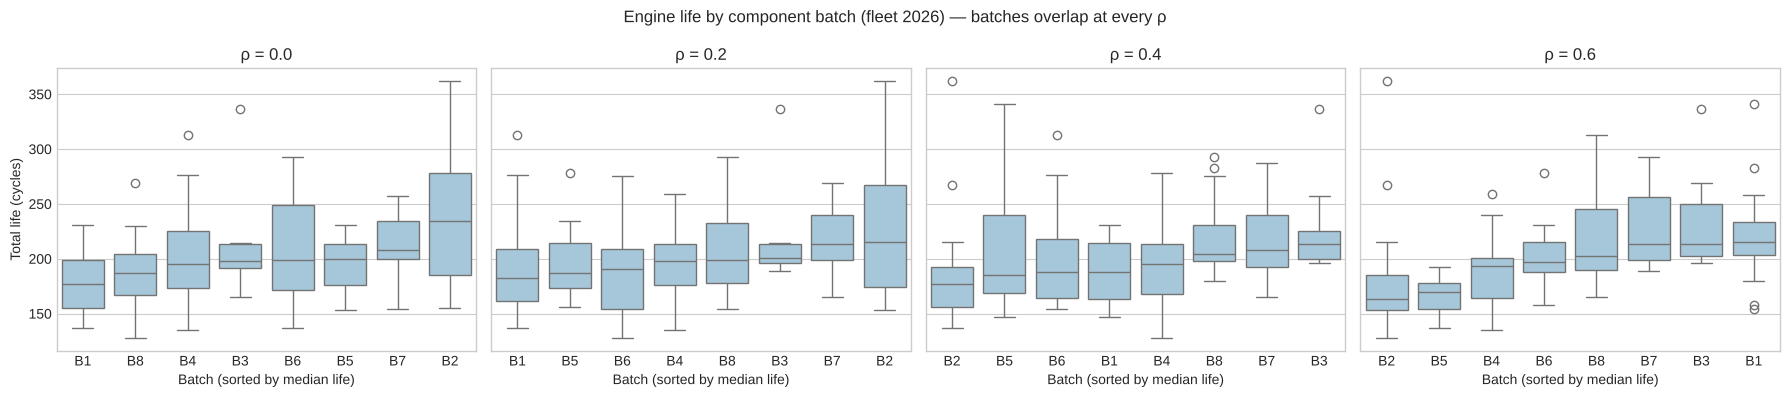

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4), sharey=True)
for ax, rho in zip(axes, RHOS):
    a = asset[rho].merge(LIFE.rename('life'), left_on='unit', right_index=True)
    order = a.groupby('component_batch')['life'].median().sort_values().index
    sns.boxplot(data=a, x='component_batch', y='life', order=order, ax=ax, color='#9ecae1')
    ax.set_title(f"ρ = {rho}")
    ax.set_xlabel('Batch (sorted by median life)')
axes[0].set_ylabel('Total life (cycles)')
fig.suptitle(f'Engine life by component batch (fleet {GEN_SEEDS[0]}) — batches overlap at every ρ')
plt.tight_layout()
plt.savefig(RESULTS_W11 / 'fig_life_by_batch.png', dpi=150)
plt.show()

## 4. Leakage checks

- **L1** Asset variables are constant within each engine (static records).
- **L2** The asset generator never opens the test file or the RUL ground-truth file.
- **L3** The hidden robustness score is never a feature (it is stored only in the audit file).
- **L4** Folds are disjoint by engine; scalers are fitted on training folds only (enforced in `prepare_fold`).
- **L5** Operational BI has no degradation link (within-engine correlation with RUL ≈ 0).
- **L6** Injected information never exceeds the design: cross-validated R² of lifetime from asset data alone stays below ρ² + 0.10, and ≤ 0.05 at ρ = 0 (mean over fleets).

In [8]:
L1 = all((train[['unit']].merge(ASSET[s][rho], on='unit').groupby('unit')[ASSET_VARS].nunique() == 1).all().all()
         for s in GEN_SEEDS for rho in RHOS)

gen_src = (PROJECT_ROOT / 'src' / 'generate_bi_asset_data.py').read_text()
L2 = ('RUL_' not in gen_src) and ('test_FD' not in gen_src) and ("test_{" not in gen_src)

L3 = all(not any('latent' in c for c in ASSET[s][rho].columns) for s in GEN_SEEDS for rho in RHOS)

L4 = all(len(set(UNITS[tr]) & set(UNITS[te])) == 0 for tr, te in folds) and \
     sorted(np.concatenate([UNITS[te] for _, te in folds])) == list(UNITS)

op = bi_op.merge(train[['unit', 'cycle', 'rul']], on=['unit', 'cycle'])
op_rho = {c: op.groupby('unit').apply(lambda g: g[c].corr(g['rul'], method='spearman')).mean()
          for c in ['downtime_penalty', 'production_priority', 'cm_cost', 'revenue_per_hour']}
L5 = all(abs(v) < 0.2 for v in op_rho.values())
print("Operational BI within-engine Spearman with RUL:", {k: round(v, 3) for k, v in op_rho.items()})

def asset_design(a):
    X = pd.get_dummies(a[ASSET_VARS], columns=['component_batch'], dtype=float)
    X['hours_since_overhaul_entry'] = np.log(X['hours_since_overhaul_entry'])
    return X.values
y_life = np.log(LIFE.loc[asset[0.0].sort_values('unit').unit].values)
ceiling = []
for s in GEN_SEEDS:
    for rho in RHOS:
        X = asset_design(ASSET[s][rho].sort_values('unit'))
        pred = cross_val_predict(RidgeCV(alphas=np.logspace(-2, 3, 20)), X, y_life,
                                 cv=GroupKFold(N_FOLDS), groups=UNITS)
        r2 = 1 - np.sum((y_life - pred) ** 2) / np.sum((y_life - y_life.mean()) ** 2)
        ceiling.append({'fleet': s, 'rho': rho, 'design_rho2': rho ** 2, 'cv_R2_life_from_asset': r2})
ceiling_df = pd.DataFrame(ceiling).groupby('rho').agg(
    design_rho2=('design_rho2', 'first'), cv_R2_life_from_asset=('cv_R2_life_from_asset', 'mean')).reset_index().round(3)
print("Mean over the 5 fleets:")
display(ceiling_df)
L6 = (ceiling_df['cv_R2_life_from_asset'] <= ceiling_df['design_rho2'] + 0.10).all() and \
     ceiling_df.loc[ceiling_df.rho == 0, 'cv_R2_life_from_asset'].iloc[0] <= 0.05

for name, ok in [('L1 static per engine', L1), ('L2 no test/RUL access', L2), ('L3 latent not a feature', L3),
                 ('L4 folds disjoint', L4), ('L5 operational BI clean', L5), ('L6 info ceiling respected', L6)]:
    print(f"{'PASS' if ok else 'FAIL'}  {name}")

Operational BI within-engine Spearman with RUL: {'downtime_penalty': np.float64(0.012), 'production_priority': np.float64(0.012), 'cm_cost': np.float64(0.157), 'revenue_per_hour': np.float64(-0.07)}


Mean over the 5 fleets:


,rho,design_rho2,cv_R2_life_from_asset
0,0.0,0.00,-0.059
1,0.2,0.04,-0.026
2,0.4,0.16,0.025
3,0.6,0.36,0.162


PASS  L1 static per engine
PASS  L2 no test/RUL access
PASS  L3 latent not a feature
PASS  L4 folds disjoint
PASS  L5 operational BI clean
PASS  L6 info ceiling respected


## 5. Cross-validated falsification battery

For each fold: fit scalers on the training engines, build sliding windows (W = 30, zero-padded as in W10) for the **time-varying** features (sensors and operational BI), flatten them with the W10 statistics, then append the **static** asset features **once** per sample. Train XGBoost and predict the RUL at each truncation point of the held-out engines.

Static features are not put inside the window: a constant repeated 30 times would produce 6 identical statistics per variable and give the trees 6 chances to split on noise.

Each finished (configuration, ρ, fleet) is cached, so an interrupted run resumes where it stopped.

In [9]:
OP_CAT = [c for c in CATEGORICAL_BI_VARS if c in bi_op.columns]
OP_CONT = [c for c in CONTINUOUS_BI_VARS if c in bi_op.columns]
OP_BIN = [c for c in OP_VARS if c not in OP_CAT + OP_CONT]
BATCH_LEVELS = [f"B{i}" for i in range(1, gba.N_BATCHES + 1)]


def build_table(op_df=None, asset_df=None):
    # Per-cycle table for all 100 engines: sensors (+ operational BI) (+ asset BI)
    df = train[['unit', 'cycle', 'rul'] + SENSOR_COLS].copy()
    if op_df is not None:
        df = df.merge(op_df[['unit', 'cycle'] + OP_VARS], on=['unit', 'cycle'], how='left')
        for c in OP_CAT:
            df[c] = pd.Categorical(df[c].astype(int), categories=sorted(bi_op[c].unique()))
        df = pd.get_dummies(df, columns=OP_CAT, dtype=float)
    if asset_df is not None:
        a = asset_df[['unit'] + ASSET_VARS].copy()
        a['component_batch'] = pd.Categorical(a['component_batch'], categories=BATCH_LEVELS)
        a = pd.get_dummies(a, columns=['component_batch'], dtype=float)
        df = df.merge(a, on='unit', how='left')           # static: join on unit only
    df['rul'] = df['rul'].clip(upper=RUL_MAX)
    return df.sort_values(['unit', 'cycle']).reset_index(drop=True)


def prepare_fold(df, train_units):
    # Scale continuous columns using statistics from the training engines only
    feats = [c for c in df.columns if c not in ('unit', 'cycle', 'rul')]
    to_scale = [c for c in feats if c in SENSOR_COLS + OP_CONT + ['prior_unplanned_removals', 'hours_since_overhaul_entry']]
    out = df.copy()
    scaler = MinMaxScaler().fit(df.loc[df.unit.isin(train_units), to_scale])
    out[to_scale] = scaler.transform(df[to_scale])
    return out, feats


def windows_all(df, feats):
    X, y = [], []
    for _, g in df.groupby('unit', sort=True):
        v = np.vstack([np.zeros((WINDOW - 1, len(feats)), np.float32), g[feats].to_numpy(np.float32)])
        t = g['rul'].to_numpy(np.float32)
        for i in range(len(t)):
            X.append(v[i:i + WINDOW]); y.append(t[i])
    return np.asarray(X), np.asarray(y)


def windows_at_cuts(df, feats, test_units):
    X, keys = [], []
    for u in test_units:
        g = df[df.unit == u]
        v_full = g[feats].to_numpy(np.float32)
        for _, c in CUTS[CUTS.unit == u].iterrows():
            v = np.vstack([np.zeros((WINDOW - 1, len(feats)), np.float32), v_full[:c.cut_cycle]])
            X.append(v[-WINDOW:]); keys.append((u, c.cut_id))
    return np.asarray(X), keys


def is_static(col):
    return col.startswith(tuple(ASSET_VARS))


def static_matrix(d, unit_list, static_cols):
    per_unit = d.groupby('unit')[static_cols].first()
    return per_unit.loc[unit_list].to_numpy(np.float32)


def run_config(name, rho, fleet, df):
    rows, importances = [], []
    for k, (tr_idx, te_idx) in enumerate(folds):
        tr_u, te_u = UNITS[tr_idx], UNITS[te_idx]
        d, feats = prepare_fold(df, tr_u)
        static_cols = [c for c in feats if is_static(c)]
        dyn_cols = [c for c in feats if not is_static(c)]

        d_tr = d[d.unit.isin(tr_u)]
        Xtr, ytr = windows_all(d_tr, dyn_cols)
        tr_units_per_sample = d_tr.sort_values(['unit', 'cycle'])['unit'].tolist()
        Xte, keys = windows_at_cuts(d, dyn_cols, te_u)

        ml = MLBranch(model_type='xgboost', flatten_strategy='statistics', random_state=SEED, **XGB_PARAMS)
        Ftr, Fte = ml._flatten(Xtr, dyn_cols), ml._flatten(Xte, dyn_cols)
        names = list(ml.feature_names_flat)
        if static_cols:
            Ftr = np.hstack([Ftr, static_matrix(d, tr_units_per_sample, static_cols)])
            Fte = np.hstack([Fte, static_matrix(d, [u for u, _ in keys], static_cols)])
            names += static_cols
        ml.model.fit(Ftr, ytr)
        pred = ml.model.predict(Fte)

        for (u, cid), p in zip(keys, pred):
            rows.append({'config': name, 'rho': rho, 'fleet': fleet, 'fold': k,
                         'unit': u, 'cut_id': cid, 'pred': float(p)})
        imp = pd.Series(ml.model.feature_importances_, index=names)
        importances.append(imp[[n for n in names if is_static(n)]].sum() / imp.sum())
    out = pd.DataFrame(rows).merge(CUTS, on=['unit', 'cut_id'])
    out['err'] = out['pred'] - out['true_rul']
    out['asset_importance_share'] = float(np.mean(importances))
    return out

In [10]:
# Configurations: (name, operational variant, asset variant). Asset variant: None, 'real', 'shuffled'.
CONFIGS = {
    '(a) Sensors':            (None,       None),
    '(b) S+Op+A':             ('real',     'real'),
    '(c) S+Op~+A~ shuffled':  ('shuffled', 'shuffled'),
    '(d) S+Op lag+A':         ('lagged',   'real'),
    '(e) S+Op only':          ('real',     None),
    '(f) S+A only':           (None,       'real'),
    '(g) S+Op~+A':            ('shuffled', 'real'),
    '(h) S+Op+A~':            ('real',     'shuffled'),
}
ASSET_FREE = [c for c, (_, a) in CONFIGS.items() if a is None]     # independent of rho and fleet

def cache_path(name, rho, fleet):
    tag = name.split(')')[0].strip('(')
    rtag = 'na' if rho is None else gba.rho_tag(rho)
    ftag = 'na' if fleet is None else str(fleet)
    q = '_quick' if QUICK else ''
    return CACHE_DIR / f"{tag}_{rtag}_{ftag}{q}.csv"

def get(name, rho=None, fleet=None):
    path = cache_path(name, rho, fleet)
    if path.exists():
        return pd.read_csv(path)
    op_kind, a_kind = CONFIGS[name]
    op_df = OP[op_kind] if op_kind else None
    a_df = None if a_kind is None else (ASSET[fleet][rho] if a_kind == 'real' else ASSET_SHUF[fleet][rho])
    out = run_config(name, np.nan if rho is None else rho, np.nan if fleet is None else fleet,
                     build_table(op_df, a_df))
    out.to_csv(path, index=False)
    return out

t0 = time.time()
parts = []
for name in ASSET_FREE:
    parts.append(get(name))
    print(f"  {name:<24} RMSE={np.sqrt(np.mean(parts[-1].err ** 2)):6.2f}")
for s in GEN_SEEDS:
    for rho in RHOS:
        for name in CONFIGS:
            if name not in ASSET_FREE:
                parts.append(get(name, rho, s))
    print(f"--- fleet {s} done ({(time.time() - t0) / 60:.1f} min)")

PRED = pd.concat(parts, ignore_index=True)
PRED.to_csv(RESULTS_W11 / 'cv_predictions.csv', index=False)
IMP = PRED.groupby(['config', 'rho', 'fleet'], dropna=False)['asset_importance_share'].first().reset_index()
print(f"\nDone in {(time.time() - t0) / 60:.1f} min — {len(PRED)} predictions")

  (a) Sensors              RMSE= 15.58
  (e) S+Op only            RMSE= 15.37
--- fleet 2026 done (0.0 min)
--- fleet 2027 done (0.0 min)
--- fleet 2028 done (0.0 min)
--- fleet 2029 done (0.0 min)


--- fleet 2030 done (0.8 min)



Done in 0.8 min — 36600 predictions


## 6. Results and statistical tests

- **Engine-level errors:** for each engine, the mean absolute error over its 3 truncation points and the 5 fleets. Paired tests compare configurations on the same 100 engines.
- **Wilcoxon signed-rank**, one-sided (is the configuration *better* than its reference?), Holm-corrected across the 4 ρ levels within each comparison.
- **Bootstrap 95% CI** of ΔRMSE (2,000 resamples of engines).

In [11]:
def unit_errors(cfg, rho=None, fleet=None):
    m = PRED[PRED.config == cfg]
    if rho is not None and m.rho.notna().any():
        m = m[np.isclose(m.rho, rho)]
    if fleet is not None and m.fleet.notna().any():
        m = m[m.fleet == fleet]
    return m.groupby('unit').agg(abs_err=('err', lambda e: np.mean(np.abs(e))),
                                 sq_err=('err', lambda e: np.mean(e ** 2))).sort_index()

def rmse(cfg, rho=None, fleet=None):
    return float(np.sqrt(unit_errors(cfg, rho, fleet).sq_err.mean()))

def holm(pvals):
    p = np.asarray(pvals, float); order = np.argsort(p); adj = np.empty_like(p); run = 0
    for i, idx in enumerate(order):
        run = max(run, (len(p) - i) * p[idx]); adj[idx] = min(run, 1.0)
    return adj

BOOT = np.random.default_rng(SEED).integers(0, len(UNITS), (2000, len(UNITS)))

def compare(cfg, ref, rho):
    a, b = unit_errors(cfg, rho), unit_errors(ref, rho)
    d = np.sqrt(a.sq_err.mean()) - np.sqrt(b.sq_err.mean())
    boots = np.sqrt(a.sq_err.values[BOOT].mean(1)) - np.sqrt(b.sq_err.values[BOOT].mean(1))
    diff = a.abs_err.values - b.abs_err.values
    p = stats.wilcoxon(diff, alternative='less').pvalue if np.any(diff != 0) else 1.0
    return {'comparison': f"{cfg}  vs  {ref}", 'config': cfg, 'reference': ref, 'rho': rho,
            'RMSE': np.sqrt(a.sq_err.mean()), 'RMSE_ref': np.sqrt(b.sq_err.mean()), 'dRMSE': d,
            'CI_low': np.percentile(boots, 2.5), 'CI_high': np.percentile(boots, 97.5), 'p_raw': p}

A, B, C, D, E, F, G, H = list(CONFIGS)
COMPARISONS = [   # (config, reference) — each evaluated at every rho, Holm across rho
    (B, A), (C, A), (D, A), (E, A), (F, A), (G, A), (H, A),   # every configuration vs sensors only
    (B, C),   # actual BI vs fully shuffled BI
    (B, D),   # aligned vs lagged operational BI
    (B, H),   # real vs shuffled asset history (with operational BI present)
    (B, G),   # real vs shuffled operational BI (with asset history present)
    (F, E),   # asset history alone vs operational alone
]
rows = []
for cfg, ref in COMPARISONS:
    fam = [compare(cfg, ref, rho) for rho in RHOS]
    for r, ph in zip(fam, holm([r['p_raw'] for r in fam])):
        r['p_holm'] = ph
    rows += fam
STATS = pd.DataFrame(rows)
STATS['sig'] = np.where(STATS.p_holm < 0.001, '***', np.where(STATS.p_holm < 0.01, '**',
               np.where(STATS.p_holm < 0.05, '*', 'ns')))
STATS.to_csv(RESULTS_W11 / 'stats_summary.csv', index=False)

rmse_A = rmse(A)
print(f"(a) Sensors only: RMSE = {rmse_A:.2f}   |   (e) S+Op only: RMSE = {rmse(E):.2f}\n")
SUMMARY = pd.DataFrame([{'config': c, **{f"ρ={r}": rmse(c, r) for r in RHOS}} for c in CONFIGS]).set_index('config')
print("RMSE by configuration and ρ (averaged over 5 fleets):")
display(SUMMARY.round(2))
print("\nPaired comparisons (Δ = config − reference; negative = config better):")
display(STATS[['comparison', 'rho', 'RMSE', 'RMSE_ref', 'dRMSE', 'CI_low', 'CI_high', 'p_holm', 'sig']].round(3))

(a) Sensors only: RMSE = 15.58   |   (e) S+Op only: RMSE = 15.37



RMSE by configuration and ρ (averaged over 5 fleets):


,ρ=0.0,ρ=0.2,ρ=0.4,ρ=0.6
config,,,,
(a) Sensors,15.58,15.58,15.58,15.58
(b) S+Op+A,15.63,15.62,15.56,15.33
(c) S+Op~+A~ shuffled,15.70,15.68,15.68,15.66
(d) S+Op lag+A,15.55,15.51,15.29,14.85
(e) S+Op only,15.37,15.37,15.37,15.37
(f) S+A only,15.61,15.51,15.34,15.08
(g) S+Op~+A,15.65,15.58,15.42,15.37
(h) S+Op+A~,15.61,15.61,15.55,15.69



Paired comparisons (Δ = config − reference; negative = config better):


,comparison,rho,RMSE,RMSE_ref,dRMSE,CI_low,CI_high,p_holm,sig
0,(b) S+Op+A vs (a) Sensors,0.0,15.633,15.576,0.057,-0.717,0.929,1.000,ns
1,(b) S+Op+A vs (a) Sensors,0.2,15.620,15.576,0.044,-0.712,0.879,1.000,ns
2,(b) S+Op+A vs (a) Sensors,0.4,15.558,15.576,-0.018,-0.761,0.822,1.000,ns
3,(b) S+Op+A vs (a) Sensors,0.6,15.330,15.576,-0.246,-1.033,0.626,1.000,ns
4,(c) S+Op~+A~ shuffled vs (a) Sensors,0.0,15.701,15.576,0.125,-0.400,0.722,1.000,ns
5,(c) S+Op~+A~ shuffled vs (a) Sensors,0.2,15.679,15.576,0.103,-0.435,0.700,1.000,ns
6,(c) S+Op~+A~ shuffled vs (a) Sensors,0.4,15.682,15.576,0.106,-0.429,0.677,1.000,ns
7,(c) S+Op~+A~ shuffled vs (a) Sensors,0.6,15.664,15.576,0.088,-0.449,0.663,1.000,ns
8,(d) S+Op lag+A vs (a) Sensors,0.0,15.551,15.576,-0.024,-1.084,1.106,0.736,ns
9,(d) S+Op lag+A vs (a) Sensors,0.2,15.509,15.576,-0.067,-1.105,1.044,0.736,ns


In [12]:
# Fleet-by-fleet consistency: ΔRMSE vs sensors only in each simulated fleet
cons = []
for s in GEN_SEEDS:
    for rho in RHOS:
        row = {'fleet': s, 'rho': rho}
        for cfg in [B, C, F, H]:
            row[cfg] = rmse(cfg, rho, s) - rmse_A
        cons.append(row)
CONS = pd.DataFrame(cons)
CONS.to_csv(RESULTS_W11 / 'fleet_consistency.csv', index=False)
CONS_SUM = pd.DataFrame({
    cfg: CONS.groupby('rho')[cfg].apply(lambda x: f"{x.mean():+.2f} (gain in {(x < 0).sum()}/{len(x)} fleets)")
    for cfg in [B, C, F, H]})
print("ΔRMSE vs sensors only — mean over fleets, and number of fleets with a gain:")
display(CONS_SUM)

ΔRMSE vs sensors only — mean over fleets, and number of fleets with a gain:


,(b) S+Op+A,(c) S+Op~+A~ shuffled,(f) S+A only,(h) S+Op+A~
rho,,,,
0.0,+0.06 (gain in 1/5 fleets),+0.12 (gain in 2/5 fleets),+0.03 (gain in 1/5 fleets),+0.04 (gain in 2/5 fleets)
0.2,+0.04 (gain in 2/5 fleets),+0.10 (gain in 1/5 fleets),-0.07 (gain in 4/5 fleets),+0.03 (gain in 2/5 fleets)
0.4,-0.02 (gain in 3/5 fleets),+0.11 (gain in 0/5 fleets),-0.24 (gain in 4/5 fleets),-0.03 (gain in 3/5 fleets)
0.6,-0.25 (gain in 4/5 fleets),+0.09 (gain in 2/5 fleets),-0.50 (gain in 4/5 fleets),+0.11 (gain in 1/5 fleets)


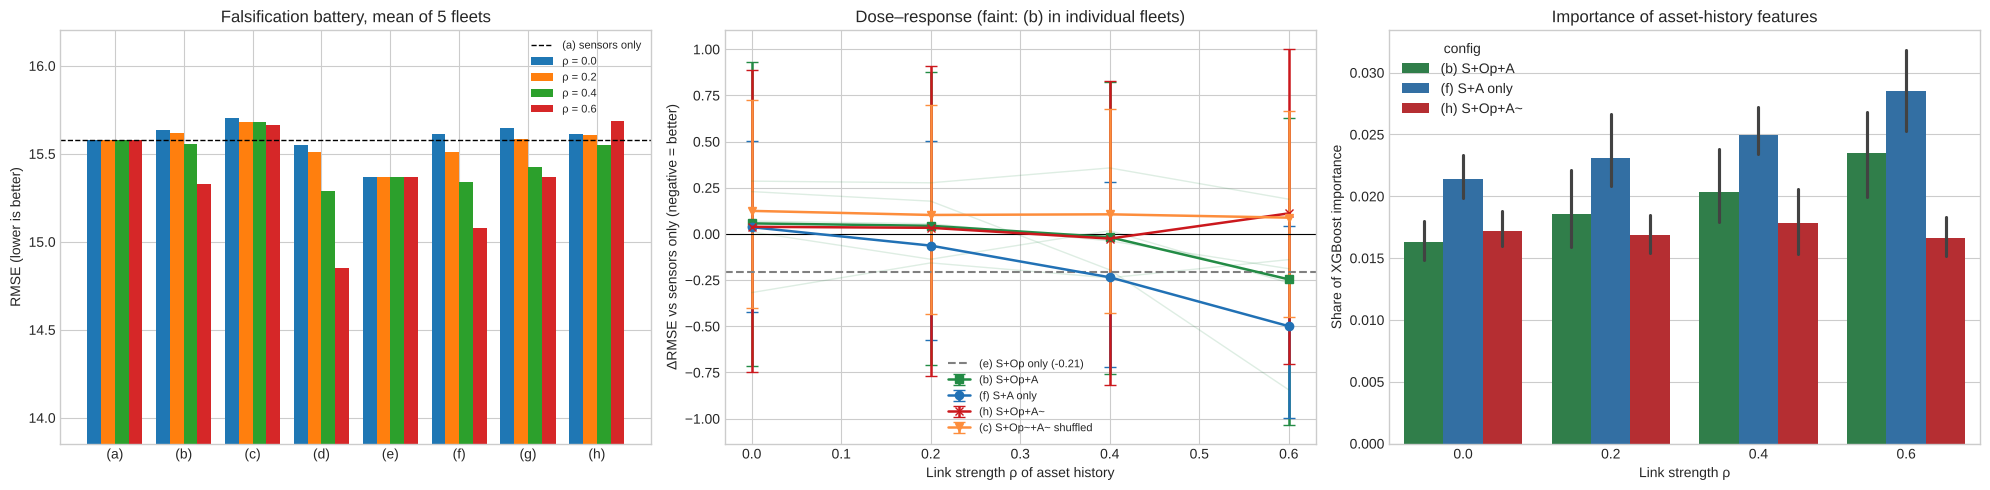

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5))

ax = axes[0]
x = np.arange(len(CONFIGS)); w = 0.2
for i, rho in enumerate(RHOS):
    ax.bar(x + (i - 1.5) * w, SUMMARY[f"ρ={rho}"], w, label=f"ρ = {rho}")
ax.axhline(rmse_A, color='black', lw=1, ls='--', label='(a) sensors only')
ax.set_xticks(x); ax.set_xticklabels([c.split(')')[0] + ')' for c in CONFIGS])
ax.set_ylim(SUMMARY.values.min() - 1, SUMMARY.values.max() + 0.5)
ax.set_ylabel('RMSE (lower is better)'); ax.set_title('Falsification battery, mean of 5 fleets'); ax.legend(fontsize=8)

ax = axes[1]
for cfg, color, marker in [(B, '#238b45', 's'), (F, '#2171b5', 'o'), (H, '#cb181d', 'x'), (C, '#fd8d3c', 'v')]:
    s_ = STATS[(STATS.config == cfg) & (STATS.reference == A)].sort_values('rho')
    ax.errorbar(s_.rho, s_.dRMSE, yerr=[s_.dRMSE - s_.CI_low, s_.CI_high - s_.dRMSE],
                label=cfg, color=color, marker=marker, capsize=4, lw=1.8)
for s in GEN_SEEDS:
    c_ = CONS[CONS.fleet == s].sort_values('rho')
    ax.plot(c_.rho, c_[B], color='#238b45', alpha=0.15, lw=1)
e_ = STATS[(STATS.config == E) & (STATS.reference == A)].dRMSE.iloc[0]
ax.axhline(e_, color='grey', ls='--', label=f"(e) S+Op only ({e_:+.2f})")
ax.axhline(0, color='black', lw=0.8)
ax.set_xlabel('Link strength ρ of asset history'); ax.set_ylabel('ΔRMSE vs sensors only (negative = better)')
ax.set_title('Dose–response (faint: (b) in individual fleets)'); ax.legend(fontsize=8)

ax = axes[2]
s_ = IMP[IMP.config.isin([B, H, F])]
sns.barplot(data=s_, x='rho', y='asset_importance_share', hue='config', ax=ax,
            palette=['#238b45', '#2171b5', '#cb181d'])
ax.set_xlabel('Link strength ρ'); ax.set_ylabel('Share of XGBoost importance'); ax.set_title('Importance of asset-history features')
plt.tight_layout()
plt.savefig(RESULTS_W11 / 'fig_falsification_combined.png', dpi=150)
plt.show()

## 7. Mechanism check — where does the gain occur?

Asset history describes the engine's starting condition, so it should help most when sensors are least informative (healthy and mid-life) and add little near failure, where sensors dominate. A gain concentrated near failure would be suspicious.

ΔRMSE of (b) S+Op+A minus (a) sensors, by life stage:


,ρ=0.0,ρ=0.2,ρ=0.4,ρ=0.6
stage,,,,
near failure (≤30),0.43,0.30,0.37,0.45
mid-life (31–80),-0.27,-0.18,-0.33,-0.77
early (>80),0.25,0.18,0.16,0.05


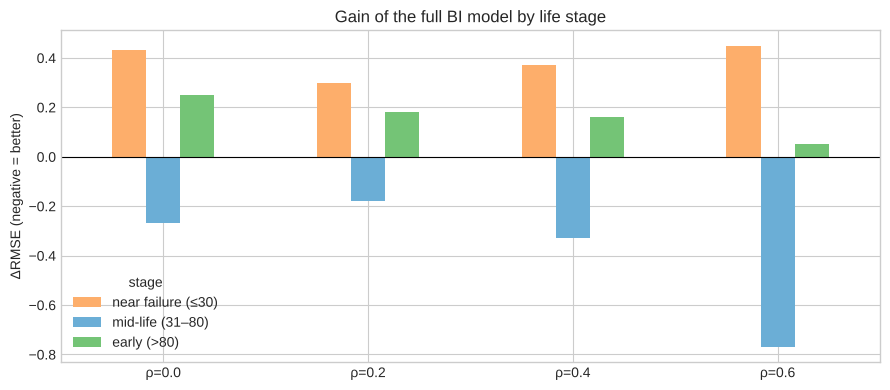

In [14]:
bins = [-1, 30, 80, RUL_MAX]
labels = ['near failure (≤30)', 'mid-life (31–80)', 'early (>80)']
ref = PRED[PRED.config == A][['unit', 'cut_id', 'err', 'true_rul']].rename(columns={'err': 'err_A'})
mech = []
for rho in RHOS:
    m = PRED[(PRED.config == B) & np.isclose(PRED.rho, rho)][['unit', 'cut_id', 'err']].merge(ref, on=['unit', 'cut_id'])
    m['stage'] = pd.cut(m.true_rul, bins=bins, labels=labels)
    g = m.groupby('stage').apply(lambda x: np.sqrt(np.mean(x.err ** 2)) - np.sqrt(np.mean(x.err_A ** 2)))
    mech.append(g.rename(f"ρ={rho}"))
MECH = pd.concat(mech, axis=1).round(2)
print("ΔRMSE of (b) S+Op+A minus (a) sensors, by life stage:")
display(MECH)
MECH.T.plot(kind='bar', figsize=(9, 4), color=['#fdae6b', '#6baed6', '#74c476'])
plt.axhline(0, color='black', lw=0.8); plt.ylabel('ΔRMSE (negative = better)')
plt.title('Gain of the full BI model by life stage'); plt.xticks(rotation=0)
plt.tight_layout(); plt.savefig(RESULTS_W11 / 'fig_gain_by_stage.png', dpi=150); plt.show()

## 8. Interpretation guide and verdict

The same five questions as W10, then an automatic checklist.

Falsification criteria:
- **F1** At ρ = 0 (no lifetime information anywhere), full BI (b) gives no significant gain over sensors.
- **F2** Fully shuffled BI (c) gives no significant gain at any ρ.
- **F3** The gain of (b) grows with ρ (Spearman correlation between ρ and ΔRMSE < 0).
- **F4** The importance of asset features in (b) rises by more than 1 point of share from ρ = 0 to 0.6, and exceeds the shuffled-asset model (h) at ρ = 0.6.
- **F5** Operational BI alone (e) gives no significant gain (consistent with W10).
- **F6** Shuffling operational BI while keeping asset history (g vs b) never matters significantly: operational BI carries no lifetime information.
- **F7** The gain of (b) is not concentrated near failure.

In [15]:
def row(cfg, ref, rho):
    return STATS[(STATS.config == cfg) & (STATS.reference == ref) & np.isclose(STATS.rho, rho)].iloc[0]

print("=" * 80); print("INTERPRETATION GUIDE (W10 questions, combined BI)"); print("=" * 80)
for rho in RHOS:
    b, c, d, f = row(B, A, rho), row(B, C, rho), row(B, D, rho), row(F, A, rho)
    e = row(E, A, rho)
    print(f"\nρ = {rho}")
    print(f"  1. Does BI add value?           (b) {b.RMSE:.2f} vs (a) {b.RMSE_ref:.2f} → Δ {b.dRMSE:+.2f} [{b.CI_low:+.2f}, {b.CI_high:+.2f}] {b.sig}")
    print(f"  2. Genuine, not noise?          (b) {c.RMSE:.2f} vs (c) {c.RMSE_ref:.2f} → Δ {c.dRMSE:+.2f} {c.sig}")
    print(f"  3. Does alignment matter?       (b) {d.RMSE:.2f} vs (d) {d.RMSE_ref:.2f} → Δ {d.dRMSE:+.2f} {d.sig}")
    print(f"  4. Help without asset history?  (e) {e.RMSE:.2f} vs (a) {e.RMSE_ref:.2f} → Δ {e.dRMSE:+.2f} {e.sig}")
    print(f"  5. Asset history alone?         (f) {f.RMSE:.2f} vs (a) {f.RMSE_ref:.2f} → Δ {f.dRMSE:+.2f} {f.sig}")

sB = STATS[(STATS.config == B) & (STATS.reference == A)].sort_values('rho')
F1 = row(B, A, 0.0).p_holm >= 0.05
F2 = (STATS[(STATS.config == C) & (STATS.reference == A)].p_holm >= 0.05).all()
F3 = stats.spearmanr(sB.rho, sB.dRMSE)[0] < 0
impB = IMP[IMP.config == B].groupby('rho').asset_importance_share.mean()
impH = IMP[IMP.config == H].groupby('rho').asset_importance_share.mean()
F4 = (impB[max(RHOS)] - impB[0.0] > 0.01) and (impB[max(RHOS)] > impH[max(RHOS)])
F5 = (STATS[(STATS.config == E) & (STATS.reference == A)].p_holm >= 0.05).all()
F6 = (STATS[(STATS.config == B) & (STATS.reference == G)].p_holm >= 0.05).all()
near, rest = MECH.loc['near failure (≤30)'], MECH.drop('near failure (≤30)').min()
F7 = bool((near.iloc[1:] >= rest.iloc[1:] - 0.5).all())

checks = [
    ('Realism', 'R1 plausible distributions', R1),
    ('Realism', 'R2 batches overlap', R2),
    ('Realism', 'R3 moderate effect sizes', R3),
    ('Leakage', 'L1 static per engine', L1),
    ('Leakage', 'L2 no test/RUL access', L2),
    ('Leakage', 'L3 latent score never a feature', L3),
    ('Leakage', 'L4 folds disjoint by engine', L4),
    ('Leakage', 'L5 operational BI degradation-free', L5),
    ('Leakage', 'L6 information ceiling respected', L6),
    ('Falsification', 'F1 no gain at ρ = 0', F1),
    ('Falsification', 'F2 no gain when all BI shuffled', F2),
    ('Falsification', 'F3 gain grows with ρ', F3),
    ('Falsification', 'F4 asset importance tracks ρ', F4),
    ('Falsification', 'F5 operational BI alone: no gain', F5),
    ('Falsification', 'F6 shuffling operational BI never matters', F6),
    ('Mechanism', 'F7 gain not concentrated near failure', F7),
]
VERDICT = pd.DataFrame(checks, columns=['family', 'check', 'pass'])
VERDICT['result'] = VERDICT['pass'].map({True: 'PASS', False: 'FAIL'})
print(); display(VERDICT[['family', 'check', 'result']])
VERDICT.to_csv(RESULTS_W11 / 'verdict.csv', index=False)
print(f"{VERDICT['pass'].sum()}/{len(VERDICT)} checks passed")

# Outcome (separate from the checks: the checks can all pass with no gain at all)
sig_b = sB[(sB.p_holm < 0.05) & (sB.dRMSE < 0)].rho.tolist()
bh = STATS[(STATS.config == B) & (STATS.reference == H)]
sig_bh = bh[(bh.p_holm < 0.05) & (bh.dRMSE < 0)].rho.tolist()
print("\nOUTCOME")
print(f"  Full BI (b) significantly better than sensors only at ρ = {sig_b if sig_b else 'none'}.")
print(f"  Real asset history significantly better than shuffled (b vs h) at ρ = {sig_bh if sig_bh else 'none'}.")
print(f"  Largest gain of (b): ΔRMSE = {sB.dRMSE.min():+.2f} at ρ = {sB.loc[sB.dRMSE.idxmin(), 'rho']}")
print("  Fleets with a gain for (b): " + ", ".join(f"ρ={r}: {(CONS[CONS.rho == r][B] < 0).sum()}/5" for r in RHOS))

INTERPRETATION GUIDE (W10 questions, combined BI)

ρ = 0.0
  1. Does BI add value?           (b) 15.63 vs (a) 15.58 → Δ +0.06 [-0.72, +0.93] ns
  2. Genuine, not noise?          (b) 15.63 vs (c) 15.70 → Δ -0.07 ns
  3. Does alignment matter?       (b) 15.63 vs (d) 15.55 → Δ +0.08 ns
  4. Help without asset history?  (e) 15.37 vs (a) 15.58 → Δ -0.21 ns
  5. Asset history alone?         (f) 15.61 vs (a) 15.58 → Δ +0.04 ns

ρ = 0.2
  1. Does BI add value?           (b) 15.62 vs (a) 15.58 → Δ +0.04 [-0.71, +0.88] ns
  2. Genuine, not noise?          (b) 15.62 vs (c) 15.68 → Δ -0.06 ns
  3. Does alignment matter?       (b) 15.62 vs (d) 15.51 → Δ +0.11 ns
  4. Help without asset history?  (e) 15.37 vs (a) 15.58 → Δ -0.21 ns
  5. Asset history alone?         (f) 15.51 vs (a) 15.58 → Δ -0.06 ns

ρ = 0.4
  1. Does BI add value?           (b) 15.56 vs (a) 15.58 → Δ -0.02 [-0.76, +0.82] ns
  2. Genuine, not noise?          (b) 15.56 vs (c) 15.68 → Δ -0.12 ns
  3. Does alignment matter?       (b) 

,family,check,result
0,Realism,R1 plausible distributions,PASS
1,Realism,R2 batches overlap,PASS
2,Realism,R3 moderate effect sizes,FAIL
3,Leakage,L1 static per engine,PASS
4,Leakage,L2 no test/RUL access,PASS
5,Leakage,L3 latent score never a feature,PASS
6,Leakage,L4 folds disjoint by engine,PASS
7,Leakage,L5 operational BI degradation-free,PASS
8,Leakage,L6 information ceiling respected,PASS
9,Falsification,F1 no gain at ρ = 0,PASS


14/16 checks passed

OUTCOME
  Full BI (b) significantly better than sensors only at ρ = none.
  Real asset history significantly better than shuffled (b vs h) at ρ = [0.6].
  Largest gain of (b): ΔRMSE = -0.25 at ρ = 0.6
  Fleets with a gain for (b): ρ=0.0: 1/5, ρ=0.2: 2/5, ρ=0.4: 3/5, ρ=0.6: 4/5


In [16]:
# Copy results to Drive (Colab only)
if SAVE_DIR is not None:
    for f in RESULTS_W11.iterdir():
        if f.is_file():
            shutil.copy(f, SAVE_DIR / f.name)
    print(f"Results copied to {SAVE_DIR}")

## 9. How to read the outcome

- **Operational BI (e, g):** expected to give no gain, as in W10. It describes the business environment, not the engine's condition; its value lies in the decision layer.
- **Asset history (b, f, h):** if F1–F7 pass and the outcome shows a significant gain at higher ρ, the framework learns lifetime-relevant business information when it exists, and only then (no gain at ρ = 0, none when shuffled). Report the dose–response curve, not a single ρ.
- **If F1, F2 or F6 fail:** something other than the asset–lifetime link drives the result (chance, overfitting). Do not report a gain; investigate first.
- **If no ρ gives a significant gain:** 100 engines are too few to learn fleet effects from static records at realistic strengths. Report this honestly as a limitation for small fleets.
- **Reporting:** state that BI variables are synthetic, describe the generation (Section 1 of the generators), and cite C-MAPSS (Saxena et al., 2008). Fleet 2026 is the reference fleet; the 5-fleet results are the robustness check.